# Fase 1: Análisis exploratorio de datos (1.2, 1.3 y 1.4)

La parte 1.1 (lectura, unificación de los archivos, checksums y análisis descriptivo) está en `notebooks/eda_1_1.ipynb`. Ese notebook genera `data/processed/dataset_unificado_0.csv`, que tiene una fila por día con el registro de las 23:59.

Acá seguimos desde ese archivo con el análisis temporal, las correlaciones y las visualizaciones, y cerramos con las conclusiones del EDA.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sys.path.append(str(Path("..") / "src"))
import preprocessing_pipeline as pp

SEMILLA = 42
carpeta_datos = Path("..") / "data"

df = pd.read_csv(carpeta_datos / "processed" / "dataset_unificado_0.csv", parse_dates=["dia"]).set_index("dia")
df = df.drop(columns="frio_kw_siguiente")
df.shape

(1213, 292)

En el 1.1 vimos que hay valores imposibles, del orden de los millones (por ejemplo `frio_kw` vale 5.572.801 el 2021-03-31). Con esos valores adentro los gráficos y las correlaciones no se pueden leer, así que para explorar los dejamos vacíos. El tratamiento definitivo de estos valores se hace en la Fase 2 (`preprocesamiento.ipynb`).

In [2]:
# Imposible: un millón o más, y además más de 5 veces la mediana de su columna
mediana = df.median()
es_imposible = (df.abs() >= 1e6) & (df.abs() > 5 * mediana.abs())
df = df.mask(es_imposible)

frio = df["frio_kw"]
# Target: el consumo del día siguiente
y = frio.shift(-1)

print("Valores imposibles vaciados:", es_imposible.sum().sum())
print("Días:", len(df), "| desde", df.index.min().date(), "hasta", df.index.max().date())
print("Días con frio_kw:", frio.notna().sum())
frio.describe().round(0).to_frame().T

Valores imposibles vaciados: 16
Días: 1213 | desde 2020-07-01 hasta 2023-10-26
Días con frio_kw: 1205


,count,mean,std,min,25%,50%,75%,max
frio_kw,1205.0,23658.0,7688.0,2310.0,17995.0,23656.0,29257.0,56128.0


# 1.2 Análisis temporal

## Evolución de `frio_kw`

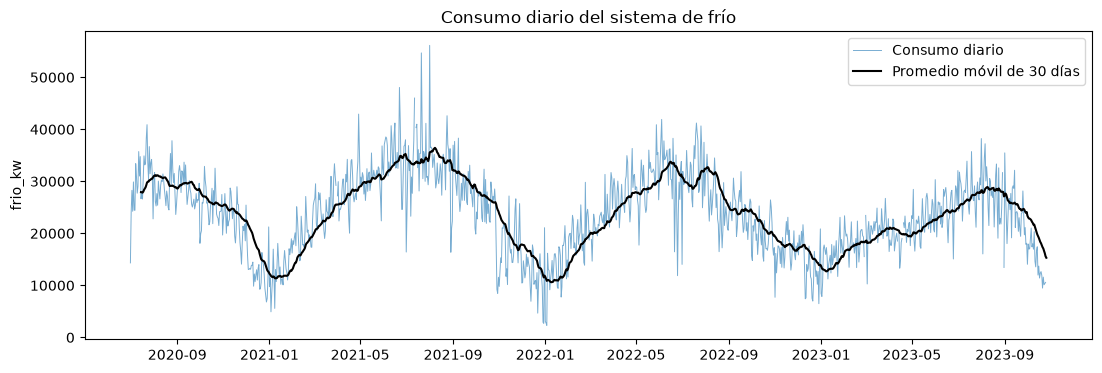

,count,mean,median,std,min,max
dia,,,,,,
2020,184,24661.0,25769.0,6990.0,6808.0,40886.0
2021,363,25231.0,26635.0,9031.0,2706.0,56128.0
2022,364,23123.0,22664.0,7648.0,2310.0,41901.0
2023,294,21751.0,21226.0,5605.0,7868.0,38215.0


In [3]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(frio.index, frio, linewidth=0.7, alpha=0.6, label="Consumo diario")
ax.plot(frio.index, frio.rolling(30, min_periods=15).mean(), color="black", label="Promedio móvil de 30 días")
ax.set_ylabel("frio_kw")
ax.set_title("Consumo diario del sistema de frío")
ax.legend()
plt.show()

frio.groupby(frio.index.year).agg(["count", "mean", "median", "std", "min", "max"]).round(0)

El consumo no es estable: sube y baja siguiendo un ciclo que se repite cada año, con picos a mitad de año y pozos entre diciembre y enero. Encima de ese ciclo hay mucho ruido de un día para el otro.

El nivel también cambió con los años. 2021 fue el año de mayor consumo y el más variable (desvío de unos 9.000 kW), y 2023 el más bajo y el más parejo (unos 5.600 kW). Esto importa para el modelado: los datos más viejos no se comportan igual que los más nuevos.

## Estacionalidad mensual y anual

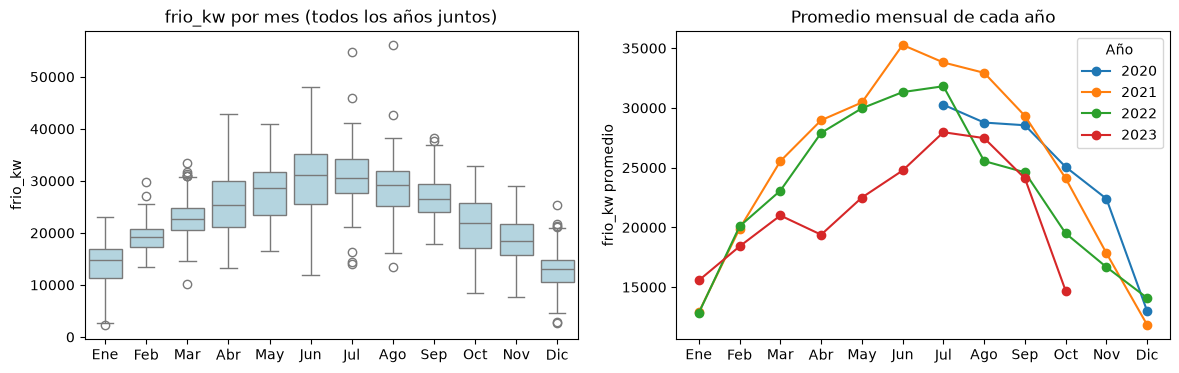

,Ene,Feb,Mar,Abr,May,Jun,Jul,Ago,Sep,Oct,Nov,Dic
frio_kw promedio,13773.0,19481.0,23180.0,25558.0,27639.0,30451.0,30939.0,28692.0,26647.0,21147.0,18971.0,12969.0


In [4]:
nombres_meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

# Boxplot por mes del año, juntando todos los años
sns.boxplot(x=frio.index.month, y=frio, ax=ax1, color="lightblue")
ax1.set_xticks(range(12))
ax1.set_xticklabels(nombres_meses)
ax1.set_xlabel("")
ax1.set_title("frio_kw por mes (todos los años juntos)")

# Promedio de cada mes, un color por año
por_mes = frio.groupby([frio.index.year, frio.index.month]).mean().unstack(0)
por_mes.plot(ax=ax2, marker="o")
ax2.set_xticks(range(1, 13))
ax2.set_xticklabels(nombres_meses)
ax2.set_xlabel("")
ax2.set_ylabel("frio_kw promedio")
ax2.set_title("Promedio mensual de cada año")
ax2.legend(title="Año")
plt.show()

promedio_mes = frio.groupby(frio.index.month).mean()
promedio_mes.index = nombres_meses
promedio_mes.round(0).to_frame("frio_kw promedio").T

La estacionalidad anual es muy marcada. El consumo promedio pasa de unos 13.000 kW en diciembre y enero a unos 31.000 kW en junio y julio: más del doble. Tiene sentido físico: la planta está en Tecate, Baja California, donde el verano es de junio a septiembre, y con más calor hace falta más frío.

El patrón se repite todos los años (gráfico de la derecha), aunque 2023 quedó por debajo de los anteriores en casi todos los meses.

Diciembre y enero tienen además los valores más bajos de toda la serie, por debajo de 5.000 kW. No parecen errores: coinciden con las fiestas, cuando la planta para o trabaja al mínimo.

## Patrón semanal

La consigna dice que hay un patrón semanal. En lugar de asumirlo, lo medimos.

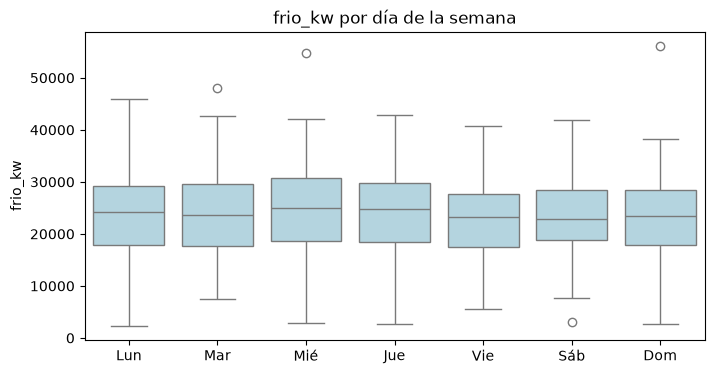

,Lun,Mar,Mié,Jue,Vie,Sáb,Dom
mean,23185.0,23917.0,24734.0,24123.0,23037.0,23282.0,23356.0
median,24132.0,23639.0,24895.0,24778.0,23214.0,22956.0,23468.0
std,7680.0,8108.0,8264.0,7455.0,6850.0,7307.0,8052.0


In [5]:
nombres_dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]

fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(x=frio.index.dayofweek, y=frio, ax=ax, color="lightblue")
ax.set_xticks(range(7))
ax.set_xticklabels(nombres_dias)
ax.set_xlabel("")
ax.set_title("frio_kw por día de la semana")
plt.show()

por_dia = frio.groupby(frio.index.dayofweek).agg(["mean", "median", "std"]).round(0)
por_dia.index = nombres_dias
por_dia.T

In [6]:
def varianza_explicada(serie, grupos):
    """Qué parte de la variación de la serie se explica por pertenecer a cada grupo (eta cuadrado).
    0 = el grupo no explica nada, 1 = lo explica todo."""
    datos = pd.DataFrame({"valor": serie, "grupo": grupos}).dropna()
    media_total = datos["valor"].mean()
    entre_grupos = datos.groupby("grupo")["valor"].agg(lambda g: len(g) * (g.mean() - media_total) ** 2).sum()
    total = ((datos["valor"] - media_total) ** 2).sum()
    return entre_grupos / total

con_dato = frio.dropna()
por_dia_semana = [con_dato[con_dato.index.dayofweek == d] for d in range(7)]
por_mes_del_anio = [con_dato[con_dato.index.month == m] for m in range(1, 13)]

medias_dia = con_dato.groupby(con_dato.index.dayofweek).mean()
medias_mes = con_dato.groupby(con_dato.index.month).mean()

pd.DataFrame({
    "diferencia_entre_el_mayor_y_el_menor_kw": [medias_dia.max() - medias_dia.min(), medias_mes.max() - medias_mes.min()],
    "diferencia_en_%_de_la_media": [(medias_dia.max() - medias_dia.min()) / con_dato.mean() * 100, (medias_mes.max() - medias_mes.min()) / con_dato.mean() * 100],
    "varianza_explicada_%": [varianza_explicada(con_dato, con_dato.index.dayofweek) * 100, varianza_explicada(con_dato, con_dato.index.month) * 100],
    "p_valor_kruskal_wallis": [stats.kruskal(*por_dia_semana).pvalue, stats.kruskal(*por_mes_del_anio).pvalue],
}, index=["Día de la semana", "Mes del año"]).round(4)

,diferencia_entre_el_mayor_y_el_menor_kw,diferencia_en_%_de_la_media,varianza_explicada_%,p_valor_kruskal_wallis
Día de la semana,1697.5795,7.1754,0.5499,0.465
Mes del año,17969.8072,75.9551,56.9959,0.000


**El patrón semanal que afirma la consigna no aparece en nuestros datos.**

- Entre el día de mayor consumo promedio (miércoles) y el de menor (viernes) hay unos 1.700 kW, un 7% de la media. Parece algo, pero dentro de cada día el consumo varía unos 7.500 kW (el desvío), así que esa diferencia queda tapada.
- El día de la semana explica el **0,5%** de la variación del consumo. El mes explica el **57%**.
- El test de Kruskal-Wallis da un p-valor de 0,47: no hay evidencia de que el consumo sea distinto según el día. Para el mes el p-valor es prácticamente cero.

¿Qué pudo haberlo borrado? El frío mantiene tanques y cámaras a temperatura las 24 horas, todos los días, se envase o no. Lo que cambia entre un martes y un domingo es la producción, pero la cerveza que ya está fermentando o guardada hay que seguir enfriándola igual. Lo que manda es la temperatura de afuera, que no sabe de días de la semana.

**Qué hacemos en consecuencia:** no esperamos que `dia_semana` y `fin_de_semana` aporten al modelo. Igual las creamos en la Fase 2, porque la consigna las sugiere, y dejamos que la selección de variables y la validación decidan con números. El `mes`, en cambio, sí debería servir.

## Patrón dentro del día

Los archivos tienen lecturas por hora de un totalizador que acumula desde las 00:00. La diferencia entre dos lecturas seguidas es lo que se consumió en esa hora. Lo calculamos con las lecturas horarias del archivo 2021-2023, usando las mismas funciones del pipeline.

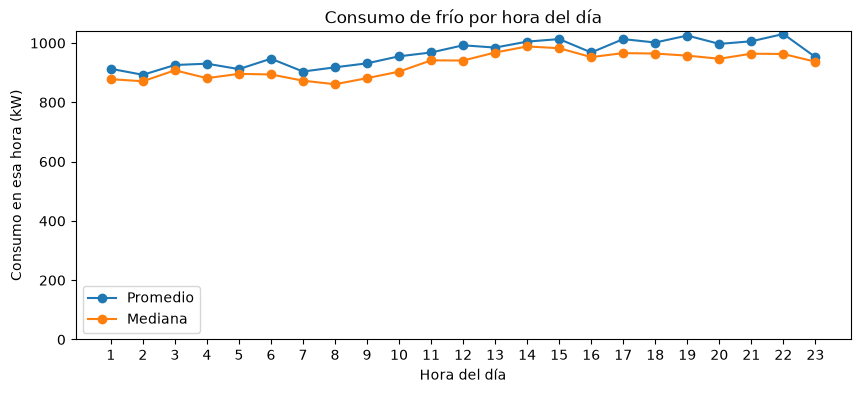

Hora de mayor consumo: 22 hs -> 1030 kW
Hora de menor consumo: 2 hs -> 893 kW
Diferencia entre la mayor y la menor: 15.4 %


In [7]:
lecturas = pp.leer_lecturas_horarias(carpeta_datos / "Totalizadores Planta - 2021_2023.xlsx")
lecturas = pp.reasignar_dias_apilados(lecturas)

# Consumo de cada hora = lectura de esa hora menos la anterior del mismo día
lecturas["consumo_hora"] = lecturas.groupby("dia")["frio_kw"].diff()
lecturas["hora_del_dia"] = (lecturas["t"] / pd.Timedelta(hours=1)).round().astype(int)

# Sacamos los saltos imposibles y los negativos, y la lectura de las 23:59 (que no es una hora entera)
horas_validas = lecturas[(lecturas["consumo_hora"] >= 0) & (lecturas["consumo_hora"] < 1e5) & (lecturas["t"] != pp.H_2359)]
perfil = horas_validas.groupby("hora_del_dia")["consumo_hora"].agg(["mean", "median"])

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(perfil.index, perfil["mean"], marker="o", label="Promedio")
ax.plot(perfil.index, perfil["median"], marker="o", label="Mediana")
ax.set_xticks(range(1, 24))
ax.set_xlabel("Hora del día")
ax.set_ylabel("Consumo en esa hora (kW)")
ax.set_title("Consumo de frío por hora del día")
ax.set_ylim(0)
ax.legend()
plt.show()

print("Hora de mayor consumo:", perfil["mean"].idxmax(), "hs ->", round(perfil["mean"].max()), "kW")
print("Hora de menor consumo:", perfil["mean"].idxmin(), "hs ->", round(perfil["mean"].min()), "kW")
print("Diferencia entre la mayor y la menor:", round((perfil["mean"].max() / perfil["mean"].min() - 1) * 100, 1), "%")

Dentro del día el consumo es bastante parejo: entre la hora de menor consumo (madrugada) y la de mayor (noche) hay un 15% de diferencia. No hay un horario de trabajo marcado, como sí lo tendría una línea de envasado. Es coherente con lo anterior: el frío funciona de corrido.

Esto también respalda una decisión de la Fase 2. Como el consumo por hora es estable, cuando a un día le falta el registro de las 23:59 pero llega hasta las 23:00, se puede estimar lo que falta con el ritmo de las últimas horas.

## ¿Cuánto se parece un día a los anteriores?

Como queremos predecir el consumo de mañana, miramos la autocorrelación: la correlación de `frio_kw` con su propio valor de 1, 2, 3... días antes.

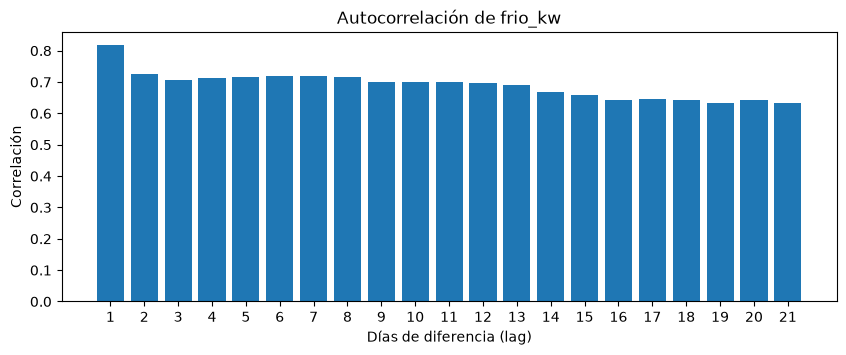

,1,2,3,7,14,21
correlación,0.819,0.726,0.705,0.72,0.669,0.633


In [8]:
autocorrelacion = pd.Series({k: frio.corr(frio.shift(k)) for k in range(1, 22)})

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(autocorrelacion.index, autocorrelacion)
ax.set_xticks(range(1, 22))
ax.set_xlabel("Días de diferencia (lag)")
ax.set_ylabel("Correlación")
ax.set_title("Autocorrelación de frio_kw")
plt.show()

autocorrelacion.loc[[1, 2, 3, 7, 14, 21]].round(3).to_frame("correlación").T

El consumo de un día se parece mucho al del día anterior (correlación de 0,82). Después baja a 0,70 y se mantiene ahí aunque comparemos con dos o tres semanas atrás. Que no siga bajando se debe a la estacionalidad: dos días separados por tres semanas están en la misma época del año.

En el lag 7 no hay un salto claro respecto de los lags vecinos, que es lo que se vería si hubiera un patrón semanal fuerte. Coincide con lo que medimos antes.

Para el modelo esto dice dos cosas: el consumo de hoy es un muy buen predictor del de mañana, y los promedios de varios días también traen información, porque marcan en qué nivel de la temporada estamos.

# 1.3 Análisis de correlaciones

Acá miramos la relación de cada variable con el **target**, que es el consumo de frío del día siguiente.

Para no mirar los datos con los que después vamos a evaluar el modelo, las correlaciones con el target las calculamos solo con el tramo de entrenamiento: el 70% más antiguo de los días, hasta el 2022-10-21. Es el mismo corte que usa el resto del proyecto.

## Variabilidad

Antes de correlacionar sacamos las columnas que casi no varían, porque una columna que no cambia no puede explicar los cambios en el consumo.

In [9]:
# Último día del tramo de entrenamiento (sale de la división 70/15/15 de src/preprocessing_pipeline.py)
FIN_TRAIN = "2022-10-21"
train = df.loc[:FIN_TRAIN]
y_train = y.loc[:FIN_TRAIN]
print("Tramo de entrenamiento:", train.index.min().date(), "a", train.index.max().date(), "|", len(train), "días")

valores_distintos = train.nunique()
faltantes = train.isna().mean() * 100
# Coeficiente de variación: desvío dividido por la media
coef_variacion = (train.std() / train.mean().abs()).replace([np.inf, -np.inf], np.nan)

poco_variables = valores_distintos[valores_distintos <= 10].index
muchos_faltantes = faltantes[faltantes > 20].index
candidatas = [c for c in df.columns if c not in poco_variables and c not in muchos_faltantes]

print("Columnas en total:", df.shape[1])
print("Con 10 valores distintos o menos:", len(poco_variables))
print("Con más de 20% de faltantes:", len(muchos_faltantes))
print("Columnas que quedan para correlacionar:", len(candidatas))

Tramo de entrenamiento: 2020-07-01 a 2022-10-21 | 843 días
Columnas en total: 292
Con 10 valores distintos o menos: 30
Con más de 20% de faltantes: 30
Columnas que quedan para correlacionar: 234


## Las 15 variables más correlacionadas con el target

Usamos Pearson y también Spearman. Pearson solo mide relaciones lineales y es muy sensible a los valores atípicos; Spearman trabaja con rangos y aguanta mejor los extremos, que en estos datos todavía hay.

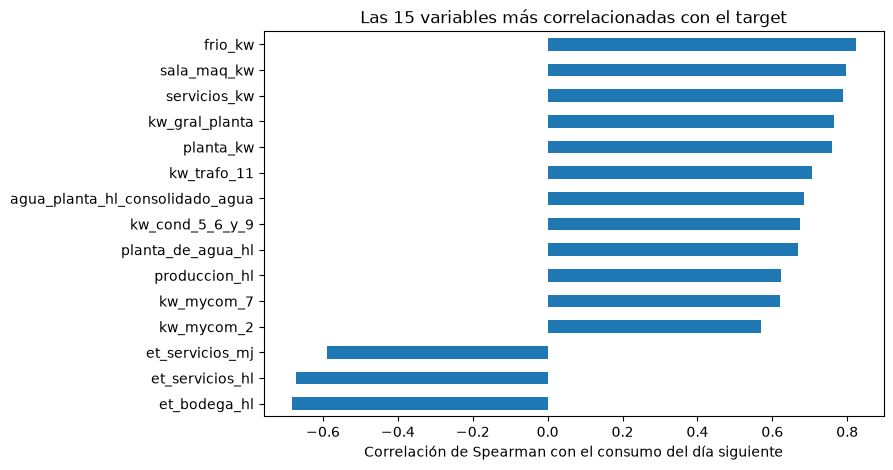

,pearson,spearman
frio_kw,0.821,0.822
sala_maq_kw,0.278,0.797
servicios_kw,0.786,0.789
kw_gral_planta,0.756,0.764
planta_kw,0.752,0.758
kw_trafo_11,0.719,0.705
agua_planta_hl_consolidado_agua,0.681,0.683
et_bodega_hl,-0.174,-0.683
kw_cond_5_6_y_9,0.681,0.674
et_servicios_hl,-0.148,-0.671


In [10]:
correlaciones = pd.DataFrame({
    "pearson": train[candidatas].corrwith(y_train),
    "spearman": train[candidatas].corrwith(y_train, method="spearman"),
})
# Ordenamos por Spearman, que es la más robusta
top15 = correlaciones.reindex(correlaciones["spearman"].abs().sort_values(ascending=False).index).head(15)

fig, ax = plt.subplots(figsize=(8, 5))
top15["spearman"].sort_values().plot.barh(ax=ax)
ax.set_xlabel("Correlación de Spearman con el consumo del día siguiente")
ax.set_title("Las 15 variables más correlacionadas con el target")
plt.show()

top15.round(3)

In [11]:
# Las más correlacionadas en sentido inverso
correlaciones.sort_values("spearman").head(5).round(3)

,pearson,spearman
et_bodega_hl,-0.174,-0.683
et_servicios_hl,-0.148,-0.671
et_servicios_mj,-0.519,-0.590
vapor_servicio_kg,-0.536,-0.567
et_planta_hl,-0.111,-0.496


La variable más correlacionada con el consumo de mañana es **el consumo de frío de hoy** (0,82). Le siguen `sala_maq_kw`, `servicios_kw`, `kw_gral_planta` y `planta_kw`, que son el consumo eléctrico de áreas cada vez más grandes que contienen al frío.

Después aparecen transformadores, condensadores y compresores (`kw_trafo_11`, `kw_cond_5_6_y_9`, `kw_mycom_7`, `kw_mycom_2`), que son equipos del propio sistema de refrigeración, y variables de agua y producción.

En `sala_maq_kw` se ve por qué miramos las dos correlaciones: Pearson da 0,28 y Spearman 0,80. La relación es fuerte, pero unos pocos valores extremos que quedan en esa columna le arruinan el coeficiente de Pearson.

Las correlaciones negativas más fuertes son de energía térmica por hectolitro (`et_bodega_hl`, `et_servicios_hl`). Lo más probable es que sea un efecto de la estación: en invierno se usa más energía térmica por hectolitro y menos frío.

## Multicolinealidad

Que dos variables estén muy correlacionadas entre sí quiere decir que traen la misma información. Miramos la matriz de correlación de las 15 de arriba.

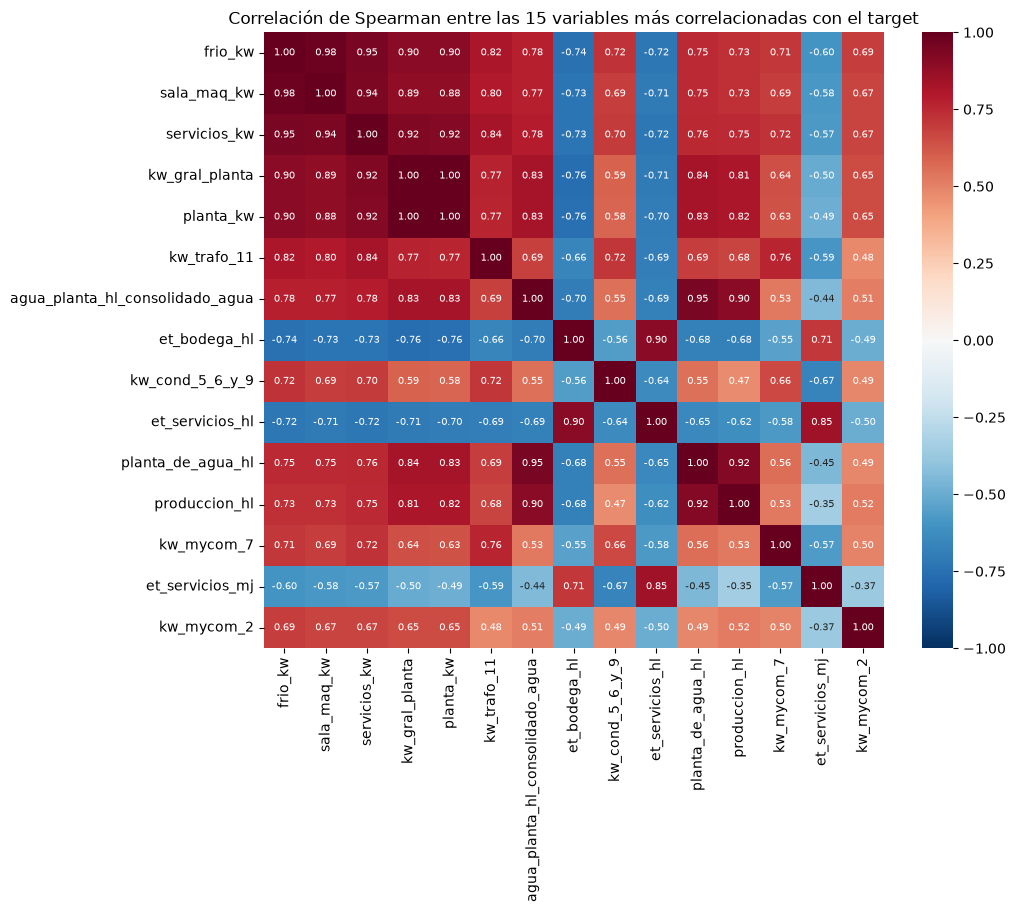

Pares con correlación mayor a 0,9: 10 de 105


,,spearman
kw_gral_planta,planta_kw,0.999
frio_kw,sala_maq_kw,0.977
agua_planta_hl_consolidado_agua,planta_de_agua_hl,0.950
frio_kw,servicios_kw,0.950
sala_maq_kw,servicios_kw,0.942
servicios_kw,kw_gral_planta,0.923
planta_de_agua_hl,produccion_hl,0.922
servicios_kw,planta_kw,0.919
agua_planta_hl_consolidado_agua,produccion_hl,0.904
frio_kw,kw_gral_planta,0.903


In [12]:
matriz = train[top15.index].corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(matriz, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, annot_kws={"size": 7})
ax.set_title("Correlación de Spearman entre las 15 variables más correlacionadas con el target")
plt.show()

# Pares con correlación mayor a 0,9
arriba = matriz.where(np.triu(np.ones(matriz.shape, dtype=bool), k=1))
pares = arriba.stack()
pares = pares[pares.abs() > 0.9].sort_values(ascending=False)
print("Pares con correlación mayor a 0,9:", len(pares), "de", int(len(matriz) * (len(matriz) - 1) / 2))
pares.round(3).to_frame("spearman")

In [13]:
# Variables que son casi una copia de frio_kw del mismo día
con_frio_de_hoy = train[candidatas].corrwith(train["frio_kw"], method="spearman").drop("frio_kw")
con_frio_de_hoy[con_frio_de_hoy.abs() > 0.9].sort_values(ascending=False).round(3).to_frame("spearman con frio_kw del mismo día")

,spearman con frio_kw del mismo día
sala_maq_kw,0.977
servicios_kw,0.950
kw_gral_planta,0.903


Hay mucha multicolinealidad. Entre las 15 variables hay varios pares con correlación mayor a 0,9, y se agrupan en dos bloques:

- **El bloque del consumo eléctrico:** `frio_kw`, `sala_maq_kw`, `servicios_kw`, `planta_kw` y `kw_gral_planta`. Estas dos últimas son prácticamente la misma variable (0,999): miden el consumo total de la planta desde dos hojas distintas.
- **El bloque de agua y producción:** `agua_planta_hl`, `planta_de_agua_hl` y `produccion_hl`.

`sala_maq_kw` y `servicios_kw` son casi una copia de `frio_kw` del mismo día (0,98 y 0,95), porque el frío es la mayor parte de la sala de máquinas y de los servicios. Usarlas para predecir el consumo de **mañana** no es trampa, porque son datos de hoy. El problema es que repiten información: una vez que el modelo tiene `frio_kw`, las otras suman poco.

Para la Fase 2 esto quiere decir que no tiene sentido quedarse con las 15: hay que elegir pocas variables que no se pisen entre sí, o usar un método que lo haga solo, como LASSO.

## Matriz de correlación entre las áreas de consumo eléctrico

La hoja Consolidado EE tiene el consumo eléctrico de cada área de la planta. Miramos cómo se relacionan entre sí.

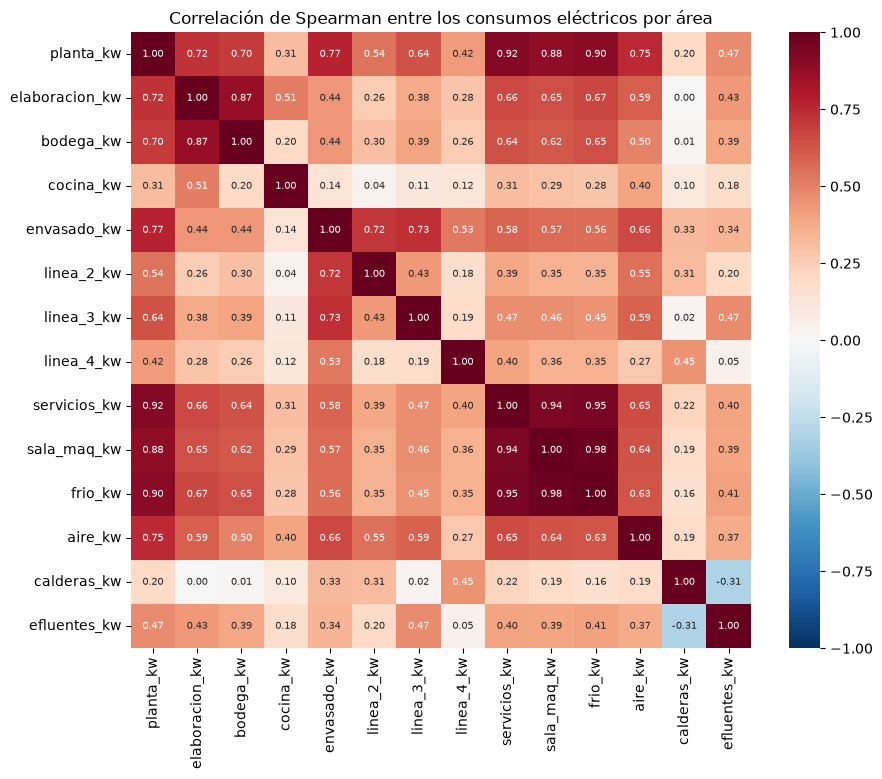

In [14]:
areas_kw = ["planta_kw", "elaboracion_kw", "bodega_kw", "cocina_kw", "envasado_kw", "linea_2_kw", "linea_3_kw",
            "linea_4_kw", "servicios_kw", "sala_maq_kw", "frio_kw", "aire_kw", "calderas_kw", "efluentes_kw"]

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(train[areas_kw].corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, annot_kws={"size": 7})
ax.set_title("Correlación de Spearman entre los consumos eléctricos por área")
plt.show()

Casi todos los consumos eléctricos están correlacionados entre sí de forma positiva: cuando la planta trabaja más, todas las áreas consumen más. El bloque más fuerte es el de `servicios_kw`, `sala_maq_kw` y `frio_kw`, que están uno adentro del otro.

# 1.4 Visualizaciones

La serie temporal de `frio_kw` y los boxplots mensuales ya están en la sección 1.2. Acá van las demás.

## Distribución del target

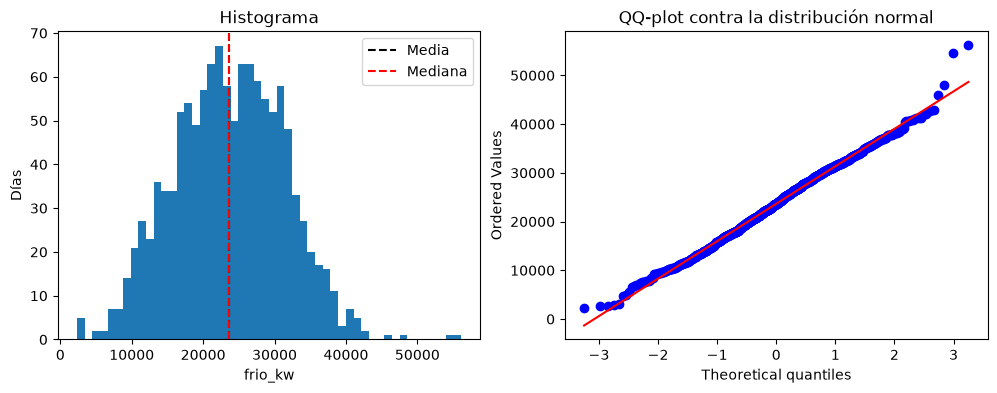

Media: 23658 | Mediana: 23656 | Desvío: 7688
Asimetría: 0.063 | Curtosis: -0.034
p-valor del test de normalidad de Shapiro-Wilk: 0.00224


In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.hist(con_dato, bins=50)
ax1.axvline(con_dato.mean(), color="black", linestyle="--", label="Media")
ax1.axvline(con_dato.median(), color="red", linestyle="--", label="Mediana")
ax1.set_xlabel("frio_kw")
ax1.set_ylabel("Días")
ax1.set_title("Histograma")
ax1.legend()

# QQ-plot: compara los cuantiles de los datos con los de una normal. Si es normal, los puntos caen sobre la recta
stats.probplot(con_dato, dist="norm", plot=ax2)
ax2.set_title("QQ-plot contra la distribución normal")
plt.show()

print("Media:", round(con_dato.mean()), "| Mediana:", round(con_dato.median()), "| Desvío:", round(con_dato.std()))
print("Asimetría:", round(con_dato.skew(), 3), "| Curtosis:", round(con_dato.kurt(), 3))
print("p-valor del test de normalidad de Shapiro-Wilk:", round(stats.shapiro(con_dato).pvalue, 5))

La distribución de `frio_kw` es simétrica y de una sola moda: la media y la mediana prácticamente coinciden (unos 23.650 kW) y la asimetría es casi cero.

En el QQ-plot los puntos siguen la recta en casi todo el rango y se despegan en las dos puntas: abajo por los días de planta parada y arriba por los picos del verano de 2021. El test de Shapiro-Wilk rechaza la normalidad (p-valor de 0,002), pero con más de 1.200 datos ese test detecta desvíos muy chicos.

En la práctica, el target no necesita ninguna transformación (logaritmo, Box-Cox) antes de modelar.

## Las 5 variables más correlacionadas contra el target

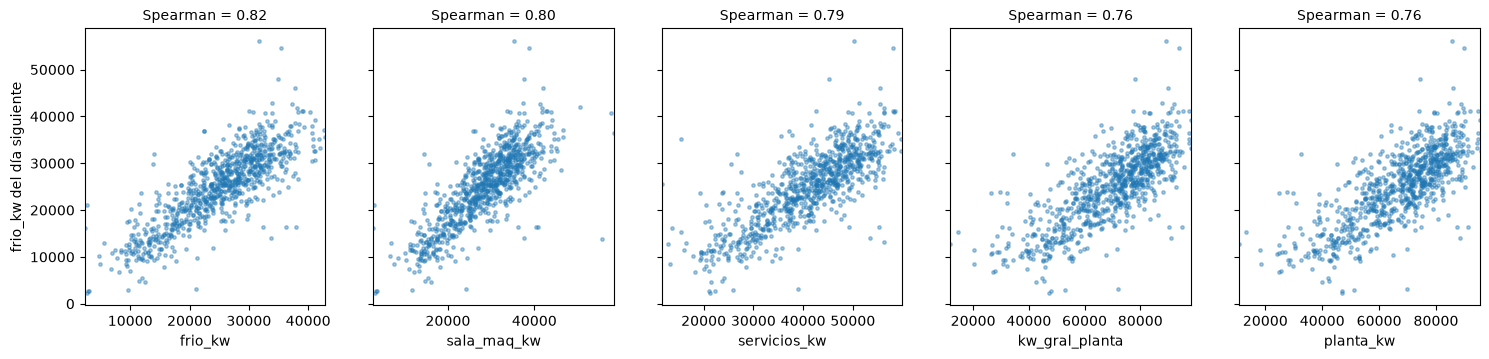

In [16]:
top5 = list(top15.index[:5])

fig, ejes = plt.subplots(1, 5, figsize=(18, 3.6), sharey=True)
for ax, variable in zip(ejes, top5):
    ax.scatter(train[variable], y_train, s=6, alpha=0.4)
    # Recortamos el eje en el percentil 99,5 para que un valor extremo no aplaste la nube
    ax.set_xlim(train[variable].min(), train[variable].quantile(0.995))
    ax.set_xlabel(variable)
    ax.set_title(f"Spearman = {top15.loc[variable, 'spearman']:.2f}", fontsize=10)
ejes[0].set_ylabel("frio_kw del día siguiente")
plt.show()

En las cinco la relación con el target es positiva y aproximadamente lineal: no se ven curvas ni grupos separados. Eso sugiere que un modelo lineal puede andar tan bien como uno más complejo.

También se ve que la nube es ancha. Con el mismo consumo de hoy, el de mañana puede variar varios miles de kW. Esa dispersión es el error que ningún modelo va a poder sacar con estas variables.

## Consumo por área de la planta

`planta_kw` es el consumo eléctrico total. Se divide en Elaboración, Envasado y Servicios, y lo que no se asigna a ninguna queda en `restos_planta_kw`. Dentro de Servicios está la sala de máquinas, y dentro de la sala de máquinas está el frío.

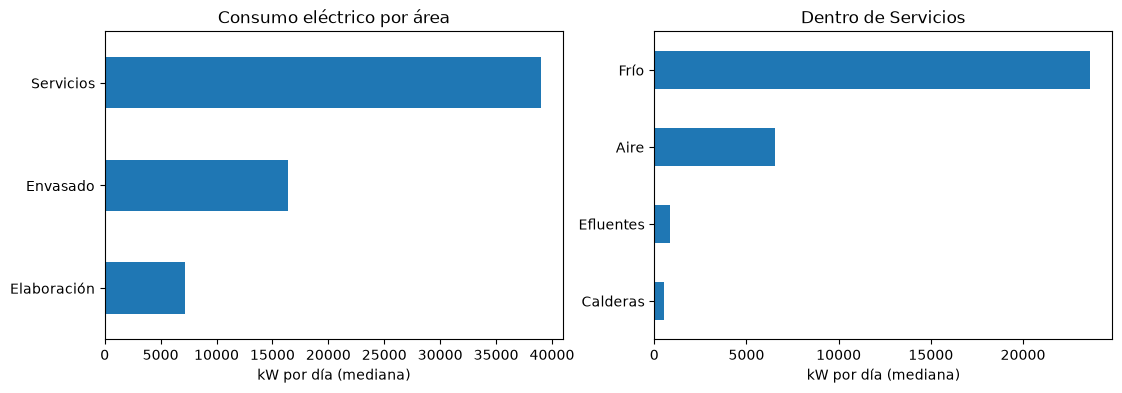

Consumo de la planta (mediana): 66852 kW por día


,kw_mediana,%_de_la_planta,spearman_con_el_target
Elaboración,7151.5,10.70,0.52
Envasado,16407.0,24.54,0.51
Servicios,39006.5,58.35,0.79
Frío,23656.0,35.39,0.82
Aire,6541.5,9.79,0.52
Calderas,511.5,0.77,0.13
Efluentes,846.5,1.27,0.39


In [17]:
areas = {
    "Elaboración": "elaboracion_kw",
    "Envasado": "envasado_kw",
    "Servicios": "servicios_kw",
}
dentro_de_servicios = {
    "Frío": "frio_kw",
    "Aire": "aire_kw",
    "Calderas": "calderas_kw",
    "Efluentes": "efluentes_kw",
}

# Usamos la mediana para que los valores atípicos no muevan el resultado
total = df["planta_kw"].median()
mediana_areas = pd.Series({nombre: df[c].median() for nombre, c in areas.items()})
mediana_servicios = pd.Series({nombre: df[c].median() for nombre, c in dentro_de_servicios.items()})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
mediana_areas.sort_values().plot.barh(ax=ax1)
ax1.set_xlabel("kW por día (mediana)")
ax1.set_title("Consumo eléctrico por área")
mediana_servicios.sort_values().plot.barh(ax=ax2)
ax2.set_xlabel("kW por día (mediana)")
ax2.set_title("Dentro de Servicios")
plt.show()

print("Consumo de la planta (mediana):", round(total), "kW por día")
resumen_areas = pd.concat([mediana_areas, mediana_servicios]).to_frame("kw_mediana")
resumen_areas["%_de_la_planta"] = resumen_areas["kw_mediana"] / total * 100
resumen_areas["spearman_con_el_target"] = [train[c].corr(y_train, method="spearman") for c in list(areas.values()) + list(dentro_de_servicios.values())]
resumen_areas.round(2)

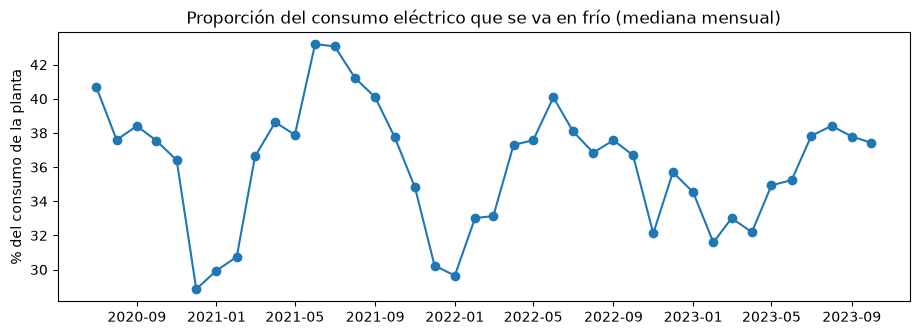

Proporción mediana: 37.1 % | mínimo mensual: 28.9 % | máximo mensual: 43.2 %


In [18]:
# Qué parte del consumo de la planta es frío, mes a mes
proporcion_frio = (df["frio_kw"] / df["planta_kw"]).where(lambda s: (s > 0) & (s < 1))
mensual = proporcion_frio.resample("MS").median() * 100

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(mensual.index, mensual, marker="o")
ax.set_ylabel("% del consumo de la planta")
ax.set_title("Proporción del consumo eléctrico que se va en frío (mediana mensual)")
plt.show()

print("Proporción mediana:", round(proporcion_frio.median() * 100, 1), "% | mínimo mensual:", round(mensual.min(), 1), "% | máximo mensual:", round(mensual.max(), 1), "%")

Servicios es el área que más electricidad consume, cerca del 58% del total de la planta, por encima de Envasado (25%) y Elaboración (11%). Y dentro de Servicios, el frío es por lejos lo más grande: solo representa alrededor del 35% de toda la electricidad de la planta.

Esa proporción no es fija. Cambia según el mes entre un 29% y un 43%, lo que confirma que el frío no sigue simplemente a la producción.

Mirando la correlación con el target, las áreas de producción (Elaboración y Envasado, cerca de 0,5) predicen el frío de mañana bastante peor que el propio frío de hoy (0,8). Nuestra hipótesis inicial era que el frío dependía sobre todo de cuánto se produce. Los datos dicen que depende más de la época del año y de su propia inercia.

# Conclusiones del EDA

1. **La estacionalidad anual domina.** El mes explica el 57% de la variación de `frio_kw`. El consumo de junio y julio es más del doble que el de diciembre y enero.
2. **No hay patrón semanal.** El día de la semana explica el 0,5% de la variación y la diferencia entre días no es significativa (p-valor de 0,47). Contradice lo que afirma la consigna, y lo atribuimos a que el frío funciona de corrido, se produzca o no.
3. **El mejor predictor del consumo de mañana es el consumo de hoy** (correlación de 0,82), y los días se parecen a los anteriores durante semanas. Los lags y los promedios móviles de `frio_kw` son las variables más prometedoras.
4. **Hay mucha redundancia.** Las variables más correlacionadas con el target miden casi lo mismo que `frio_kw`. Hay que quedarse con pocas.
5. **El target es simétrico** y no necesita transformación. La relación con sus mejores predictores es aproximadamente lineal.
6. **El frío es el mayor consumo eléctrico de la planta** (alrededor del 35% del total) y depende más de la época del año que de la producción del día.
7. **Los datos tienen problemas de calidad** que hay que tratar antes de modelar: valores imposibles del orden de los millones, valores negativos, columnas con muchos faltantes y días sin registro.

## Qué hacemos con esto en la Fase 2

- Limpiar los valores imposibles, los negativos y los faltantes.
- Crear promedios móviles de `frio_kw` y variables de calendario.
- Probar las variables de día de la semana, pero sin esperar que aporten.
- Seleccionar pocas variables, usando solo los datos de entrenamiento.